In [14]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import os

In [15]:
# 성별 / 연령대
data1 = pd.read_csv("", sep='|')

FileNotFoundError: [Errno 2] No such file or directory: 'import_data/TB_CKDATA_FLOATING_POPULATION_GENDER_AGE_DAY_TIME/seoul_flow_age_202401.csv'

In [ ]:
# data1.info()

In [ ]:
gdf1 = gpd.GeoDataFrame(data1, geometry = gpd.points_from_xy(data1["X_COORD"], data1["Y_COORD"]),
                       crs="EPSG:5179")
gdf1= gdf1.to_crs("EPSG:4326")
gdf1["lon"] = gdf1.geometry.x
gdf1["lat"] = gdf1.geometry.y

In [ ]:
# 시간대

data2 = pd.read_csv("", sep='|')

In [ ]:
gdf2 = gpd.GeoDataFrame(data2, geometry = gpd.points_from_xy(data2["X_COORD"], data2["Y_COORD"]),
                       crs="EPSG:5179")
gdf2= gdf2.to_crs("EPSG:4326")
gdf2["lon"] = gdf2.geometry.x
gdf2["lat"] = gdf2.geometry.y

In [ ]:
# 요일별

data3 = pd.read_csv("", sep='|')
# data3.info()

In [ ]:
gdf3 = gpd.GeoDataFrame(data3, geometry = gpd.points_from_xy(data3["X_COORD"], data3["Y_COORD"]),
                       crs="EPSG:5179")
gdf3= gdf3.to_crs("EPSG:4326")
gdf3["lon"] = gdf3.geometry.x
gdf3["lat"] = gdf3.geometry.y

In [ ]:
# 성별 / 나이 + 시간대 + 요일별 병합

In [4]:
mg1 = gdf1.merge(gdf2, on = ["X_COORD", "Y_COORD", "STD_YM","geometry",'lon','lat'], how = 'left')
result = mg1.merge(gdf3, on = ['X_COORD', "Y_COORD","STD_YM","geometry",'lon','lat'], how = 'left')
# result.info()

NameError: name 'gdf1' is not defined

In [5]:
# result[["X_COORD", "Y_COORD", "lon", "lat"]].head()

In [6]:
gdf_wgs = result.to_crs("EPSG:4326")

NameError: name 'result' is not defined

In [7]:
# fig, ax = plt.subplots(figsize=(8, 8))
# gdf_wgs.plot(ax=ax, markersize=3)
# ax.set_title("Seoul")
# plt.show()

In [8]:
import geopandas as gpd
import os

# 파일 경로 설정 (사용자의 실제 경로로 변경 필요)
file_path = "" 

# 1. SHAPE_RESTORE_SHX 설정 시도 (오류 메시지에 따른 직접적인 해결책)
# 라이브러리 환경 변수 설정을 시도합니다.
os.environ['SHAPE_RESTORE_SHX'] = 'YES'

try:
    # 2. 파일을 다시 읽어 봅니다.
    # print("=== SHAPE_RESTORE_SHX 설정을 적용하여 파일을 다시 읽습니다. ===")
    geumcheon = gpd.read_file(file_path)
    # print("성공")
    # print(geumcheon.head())

except FileNotFoundError:
    print(f"오류: 파일을 찾을 수 없습니다. 파일 경로 '{file_path}'를 확인해주세요.")
except Exception as e:
    print(f"데이터 로딩 중 다른 오류가 발생했습니다: {e}")

데이터 로딩 중 다른 오류가 발생했습니다: upload/GeumcheonAdministrativeDongBoundary.shp: No such file or directory


In [9]:
# print(geumcheon.total_bounds)

In [10]:
geumcheon = geumcheon.set_crs(epsg=5179)

geumcheon = geumcheon.to_crs(gdf_wgs.crs)

geumcheon_pop = gpd.sjoin(
    gdf_wgs,
    geumcheon,
    predicate="within"
)

NameError: name 'geumcheon' is not defined

In [11]:
# fig, ax = plt.subplots(figsize=(8, 8))
# geumcheon_pop.plot(ax=ax, markersize=3)
# ax.set_title("Geumcheon")
# plt.show()

NameError: name 'geumcheon_pop' is not defined

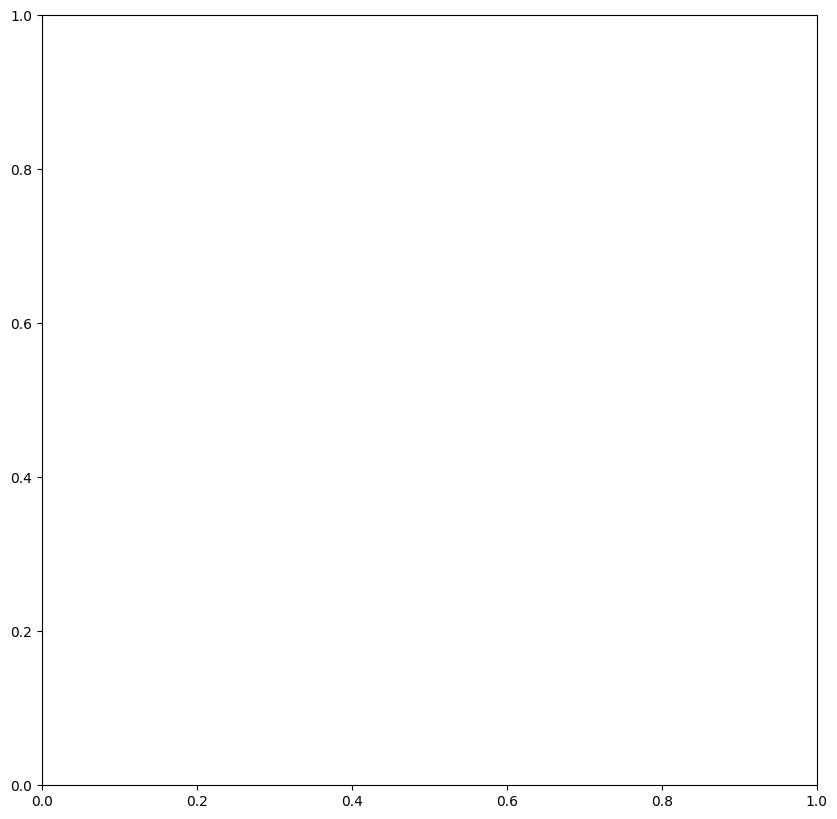

In [12]:

fig, ax = plt.subplots(1, 1, figsize=(10, 10))

geumcheon_pop.plot(
        ax=ax,
        column="WMAN_FLOW_POP_CNT_60GU", # <-- 요청하신 컬럼명
        cmap="OrRd", # 시각화 색상 맵 (빨강 계열)
        legend=True, # 범례 표시
        markersize=100 # 마커 크기 조정
    )

ax.set_title("Donggeun no SSlmo")
ax.set_axis_off()
plt.show()